In [1]:
import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Visualizations folder create karna agar exist na kare
vis_dir = os.path.abspath(
    os.path.join(
        os.path.dirname(__file__)
        if '__file__' in locals()
        else os.path.abspath(''),
        '..',
        'visualizations',
    )
)
os.makedirs(vis_dir, exist_ok=True)

# Task 1 ka cleaned dataset load karna
dataset_path = os.path.abspath(
    os.path.join(
        os.path.dirname(__file__)
        if '__file__' in locals()
        else os.path.abspath(''),
        '..',
        '..',
        'Task_1_Netflix_Data_Cleaning',
        'output',
        'netflix_cleaned.csv',
    )
)

df = pd.read_csv(dataset_path)

print('Cleaned Dataset Loaded Successfully!')
print(f'Total Records: {len(df)}')
df.head(3)

Cleaned Dataset Loaded Successfully!
Total Records: 8790


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"


In [2]:
# Multi-country entries ko split and explode karna
df_countries = df.copy()
df_countries["country"] = df_countries["country"].str.split(", ")
df_countries = df_countries.explode("country")

# Top 10 content producing countries nikalna
top_10 = df_countries["country"].value_counts().head(10)

print("Top 10 Content Producing Countries on Netflix:")
print(top_10)

Top 10 Content Producing Countries on Netflix:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Unknown            287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_27760\2059701054.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10.values, y=top_10.index, palette="mako")


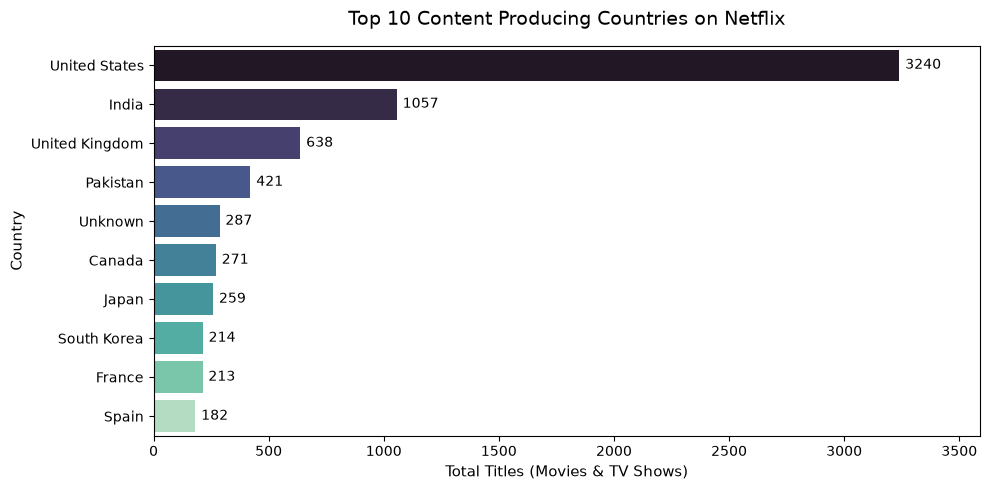

Chart saved successfully at: c:\Users\Lenovo\Downloads\Auspify_Internship\Task_3_Country_Analysis\visualizations\top_10_countries.png


In [3]:
# Chart 1: Top 10 Countries Bar Plot
plt.figure(figsize=(10, 5))
sns.barplot(x=top_10.values, y=top_10.index, palette="mako")

plt.title("Top 10 Content Producing Countries on Netflix", fontsize=14, pad=15)
plt.xlabel("Total Titles (Movies & TV Shows)", fontsize=11)
plt.ylabel("Country", fontsize=11)

# Numbers ko bar ke aage annotate karna
for index, value in enumerate(top_10.values):
  plt.text(value + 25, index, str(value), va="center", fontsize=10)

plt.xlim(0, max(top_10.values) + 350)
plt.tight_layout()

# Image ko visualizations folder me auto-save karna
chart1_path = os.path.join(vis_dir, "top_10_countries.png")
plt.savefig(chart1_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Chart saved successfully at: {chart1_path}")

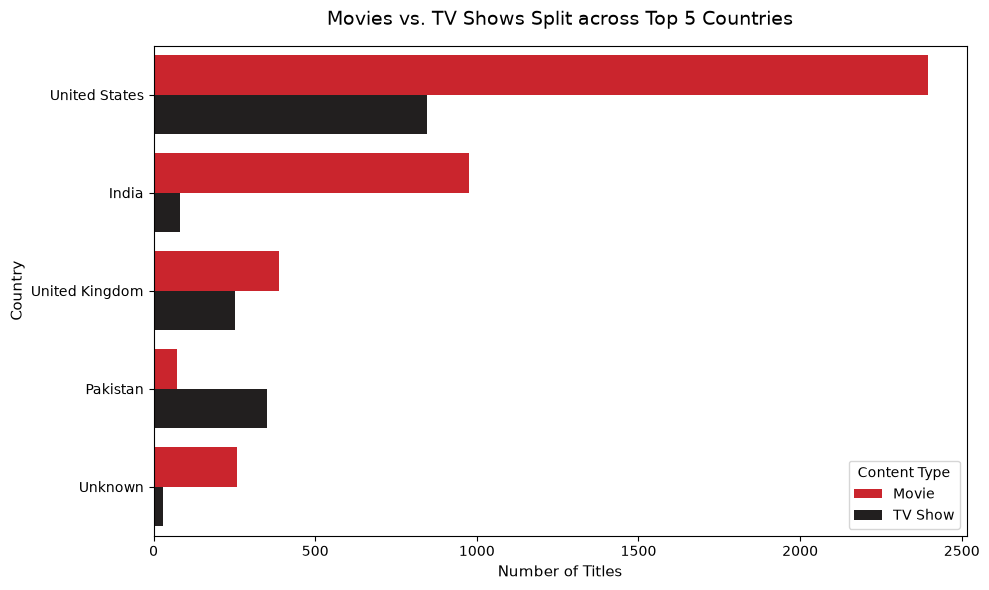

Chart saved successfully at: c:\Users\Lenovo\Downloads\Auspify_Internship\Task_3_Country_Analysis\visualizations\movie_tv_split_top5.png


In [4]:
# Filter for Top 5 countries only
top_5_names = top_10.head(5).index
df_top5 = df_countries[df_countries['country'].isin(top_5_names)]

# Chart 2: Movies vs TV Shows Breakdown (Top 5 Countries)
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_top5,
    y='country',
    hue='type',
    order=top_5_names,
    palette=['#E50914', '#221F1F']
)

plt.title('Movies vs. TV Shows Split across Top 5 Countries', fontsize=14, pad=15)
plt.xlabel('Number of Titles', fontsize=11)
plt.ylabel('Country', fontsize=11)
plt.legend(title='Content Type')

plt.tight_layout()

# Save chart to visualizations folder
chart2_path = os.path.join(vis_dir, 'movie_tv_split_top5.png')
plt.savefig(chart2_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Chart saved successfully at: {chart2_path}")

In [5]:
report_path = os.path.abspath(
    os.path.join(
        os.path.dirname(__file__)
        if '__file__' in locals()
        else os.path.abspath(''),
        '..',
        'reports',
        'country_analysis_summary.txt',
    )
)

summary_text = """Auspify Technologies - Task 3: Country-Wise Netflix Content Analysis
========================================================================

Key Insights:
1. Top Producing Nation: United States leads globally with 3,240 titles.
2. Second Highest: India holds the #2 spot with 1,057 titles, heavily dominated by feature films.
3. Content Format Preference:
   - India and United States produce significantly more Movies than TV Shows.
   - United Kingdom shows a relatively balanced mix between series and movies.
4. Total Unique Records Analyzed: 8,790 cleaned Netflix titles.

Generated Outputs:
- visualizations/top_10_countries.png
- visualizations/movie_tv_split_top5.png
"""

with open(report_path, "w") as f:
  f.write(summary_text)

print(f"Report generated successfully at: {report_path}")

Report generated successfully at: c:\Users\Lenovo\Downloads\Auspify_Internship\Task_3_Country_Analysis\reports\country_analysis_summary.txt
